<a href="https://colab.research.google.com/github/Ouissal-Ab/TP-MLP-DryBean/blob/main/TP_MLP_DryBean.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Installation


In [1]:
!pip install ucimlrepo

Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

SEED = 42
keras.utils.set_random_seed(SEED)
print("TensorFlow :", tf.__version__)
plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 11})

TensorFlow : 2.21.0


**Interprétation :** Au début le réseau répond presque au hasard. Grâce à fit, qui répète la propagation avant, le calcul de l'erreur, la rétropropagation et la mise à jour des poids, la perte diminue jusqu'à presque 0 et le réseau finit par classer correctement les 4 cas de XNOR.

x1 x2 | cible | probabilité initiale | finale | décision
[[0.         0.         1.         0.5        0.99907544 1.        ]
 [0.         1.         0.         0.41086294 0.00300052 0.        ]
 [1.         0.         0.         0.60371855 0.00306072 0.        ]
 [1.         1.         1.         0.52542099 0.99673409 1.        ]]


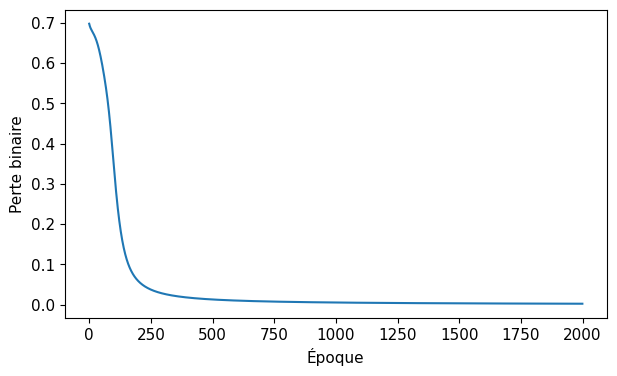

In [3]:
class MiniMLP:
    def __init__(self, seed=5):
        rng = np.random.default_rng(seed)
        self.W1 = rng.normal(0, 1/np.sqrt(2), (2, 3))
        self.b1 = np.zeros((1, 3))
        self.W2 = rng.normal(0, 1/np.sqrt(3), (3, 1))
        self.b2 = np.zeros((1, 1))

    def forward(self, X):

        H = np.tanh(X @ self.W1 + self.b1)
        Z = H @ self.W2 + self.b2
        P = np.exp(-np.logaddexp(0, -Z))
        return H, Z, P

    def fit(self, X, y, epochs=2000, rate=0.5):
        losses = []
        for _ in range(epochs):
            H, Z, P = self.forward(X)

            losses.append(float(np.mean(np.logaddexp(0, Z) - y*Z)))

            D2 = (P-y)/len(y)
            dW2 = H.T @ D2
            db2 = D2.sum(axis=0, keepdims=True)
            D1 = (D2 @ self.W2.T) * (1-H**2)
            dW1 = X.T @ D1
            db1 = D1.sum(axis=0, keepdims=True)

            self.W1 -= rate*dW1
            self.b1 -= rate*db1
            self.W2 -= rate*dW2
            self.b2 -= rate*db2
        return losses

X_logic = np.array([[0.,0.],[0.,1.],[1.,0.],[1.,1.]])
y_logic = np.array([[1.],[0.],[0.],[1.]])
mini = MiniMLP()
initial_prob = mini.forward(X_logic)[2].copy()
logic_loss = mini.fit(X_logic, y_logic)
final_prob = mini.forward(X_logic)[2]
print("x1 x2 | cible | probabilité initiale | finale | décision")
print(np.column_stack([X_logic, y_logic, initial_prob, final_prob,
                      (final_prob >= 0.5).astype(int)]))
plt.plot(logic_loss)
plt.xlabel("Époque")
plt.ylabel("Perte binaire")
plt.show()
assert np.array_equal((final_prob >= 0.5).astype(int), y_logic.astype(int))

Chargement

**Interprétation :** Le dataset contient 13 611 grains de haricots, chacun décrit par 16 mesures (X). y contient la variété de chaque grain.

In [4]:
dry_bean = fetch_ucirepo(id=602)

X_df = dry_bean.data.features
y_raw = dry_bean.data.targets.values.ravel()

print(X_df.shape)
print(y_raw.shape)

(13611, 16)
(13611,)


Exploration

**Interprétation :** Il n'y a aucune valeur manquante. Les variables ont des échelles très différentes : Area va jusqu'à 250 000 alors que les ShapeFactor sont autour de 0,001, donc il faudra standardiser les données. Les classes sont déséquilibrées : DERMASON est la plus fréquente (3 546 grains) et BOMBAY la plus rare (522 grains). Il faudra garder ces proportions lors de la séparation.

['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRatio', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'Roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']
                         mean           min            max
Area             53048.284549  20420.000000  254616.000000
Perimeter          855.283459    524.736000    1985.370000
MajorAxisLength    320.141867    183.601165     738.860154
MinorAxisLength    202.270714    122.512653     460.198497
AspectRatio          1.583242      1.024868       2.430306
Eccentricity         0.750895      0.218951       0.911423
ConvexArea       53768.200206  20684.000000  263261.000000
EquivDiameter      253.064220    161.243764     569.374358
Extent               0.749733      0.555315       0.866195
Solidity             0.987143      0.919246       0.994677
Roundness            0.873282      0.489618       0.990685
Compactness          0.799864      0.640577       0.9873

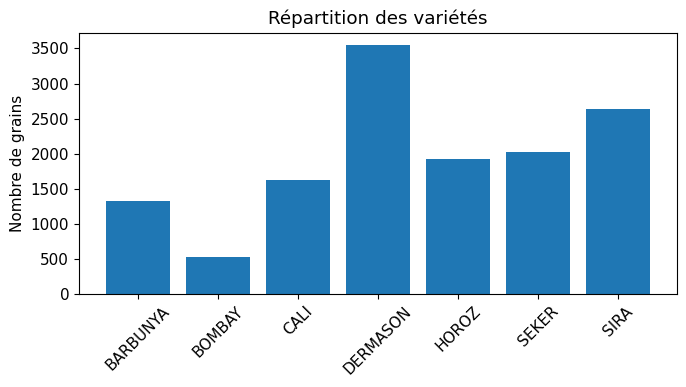

In [5]:
print(X_df.columns.tolist())
print(X_df.describe().T[["mean", "min", "max"]])
print("Valeurs manquantes :", X_df.isna().sum().sum())

classes, effectifs = np.unique(y_raw, return_counts=True)
for c, n in zip(classes, effectifs):
    print(f"{c:10s} : {n}")

plt.bar(classes, effectifs)
plt.xticks(rotation=45)
plt.ylabel("Nombre de grains")
plt.title("Répartition des variétés")
plt.tight_layout()
plt.show()

Encodage des classes

**Interprétation :** LabelEncoder a transformé les noms des variétés en nombres de 0 à 6 (par ordre alphabétique), car Keras a besoin de classes sous forme d'entiers. Ces nombres sont seulement des étiquettes, ils n'ont pas d'ordre. On garde cette correspondance pour retrouver le nom de la variété après la prédiction.

In [6]:

encoder = LabelEncoder()
y = encoder.fit_transform(y_raw).astype("int64")
X = X_df.values.astype("float32")
class_names = encoder.classes_
n_features = X.shape[1]
n_classes = len(class_names)

print("Correspondance :", dict(zip(class_names, range(n_classes))))
print("X :", X.shape, "y :", y.shape)

Correspondance : {'BARBUNYA': 0, 'BOMBAY': 1, 'CALI': 2, 'DERMASON': 3, 'HOROZ': 4, 'SEKER': 5, 'SIRA': 6}
X : (13611, 16) y : (13611,)


Séparation et scaler

**Interprétation :** Les données sont bien séparées en environ 60 % train (8 166), 20 % validation (2 722) et 20 % test (2 723), avec les mêmes proportions de classes grâce à stratify. Le scaler est ajusté seulement sur le train, puis appliqué à la validation et au test, pour éviter que le modèle profite d'informations qu'il ne devrait pas connaître.

In [7]:
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=SEED)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

print("Train / validation / test :", len(y_train), len(y_val), len(y_test))
assert np.allclose(scaler.mean_, X_train.mean(axis=0), rtol=1e-4)

Train / validation / test : 8166 2722 2723


Modèle

**Interprétation :** Le réseau a une seule couche cachée de 32 neurones et une couche de sortie de 7 neurones, une par variété. Il a 775 paramètres au total : 544 pour la couche cachée et 231 pour la sortie . Tous ces poids et biais seront ajustés pendant l'apprentissage.

In [8]:
model = keras.Sequential([
    keras.Input(shape=(n_features,)),
    layers.Dense(32, activation="relu"),
    layers.Dense(n_classes, activation="softmax")
])
model.summary()
print("Paramètres :", model.count_params())
assert model.count_params() == (16*32 + 32) + (32*7 + 7)   # = 775

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 775 (3.03 KB)

 Trainable params: 775 (3.03 KB)

 Non-trainable params: 0 (0.00 B)

Paramètres : 775


Compile

In [10]:
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
              loss=keras.losses.SparseCategoricalCrossentropy(),
              metrics=["accuracy"])

Fit

**Interprétation :** Le modèle a été entraîné pendant les 40 époques demandées. À chaque époque, les 8 166 grains du train sont découpés en 256 lots de 32, donc les poids sont mis à jour 256 fois par époque. La validation ne sert pas à modifier les poids, seulement à mesurer la perte et l'accuracy à la fin de chaque époque, ce qui donne les 4 courbes disponibles.

In [11]:
history = model.fit(X_train_s, y_train,
                    validation_data=(X_val_s, y_val),
                    epochs=40, batch_size=32, verbose=0)
print("Courbes disponibles :", list(history.history))
print("Époques exécutées :", len(history.history["loss"]))
print("Nombre de lots par époque :", int(np.ceil(len(y_train) / 32)))

Courbes disponibles : ['accuracy', 'loss', 'val_accuracy', 'val_loss']
Époques exécutées : 40
Nombre de lots par époque : 256


Courbes

**Interprétation :** La perte baisse très vite pendant les 5 premières époques, puis se stabilise autour de 0,2. L'accuracy monte rapidement et se stabilise autour de 93 % pour le train et la validation. Les deux courbes sont presque collées, donc il n'y a pas de surapprentissage : le modèle se comporte aussi bien sur des données qu'il n'a pas vues. Après 10 époques, la perte diminue très peu, donc continuer l'entraînement n'améliore presque plus le modèle.

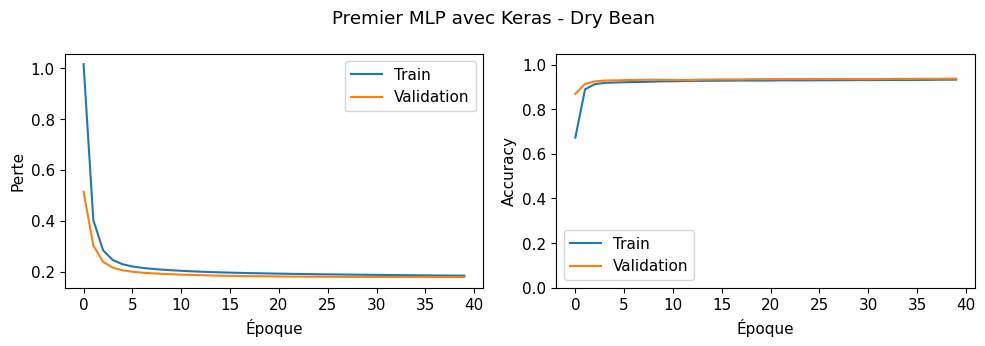

In [12]:
def plot_history(history, title):
    h = history.history
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(h["loss"], label="Train")
    axes[0].plot(h["val_loss"], label="Validation")
    axes[0].set(xlabel="Époque", ylabel="Perte")
    axes[1].plot(h["accuracy"], label="Train")
    axes[1].plot(h["val_accuracy"], label="Validation")
    axes[1].set(xlabel="Époque", ylabel="Accuracy", ylim=(0, 1.05))
    for ax in axes:
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_history(history, "Premier MLP avec Keras - Dry Bean")

Évaluation sur validation

**Interprétation :** Le modèle obtient 93,7 % d'accuracy sur la validation. BOMBAY est parfaitement reconnue, mais SIRA et DERMASON sont souvent confondues car leurs grains se ressemblent, ce qui fait de SIRA la classe la moins bien prédite.

Évaluation : {'accuracy': 0.9371785521507263, 'loss': 0.1784835010766983}
Probabilités : (2722, 7)
              precision    recall  f1-score   support

    BARBUNYA      0.935     0.924     0.930       264
      BOMBAY      1.000     1.000     1.000       105
        CALI      0.933     0.933     0.933       326
    DERMASON      0.927     0.944     0.935       709
       HOROZ      0.959     0.959     0.959       386
       SEKER      0.980     0.963     0.971       405
        SIRA      0.895     0.890     0.892       527

    accuracy                          0.937      2722
   macro avg      0.947     0.945     0.946      2722
weighted avg      0.937     0.937     0.937      2722



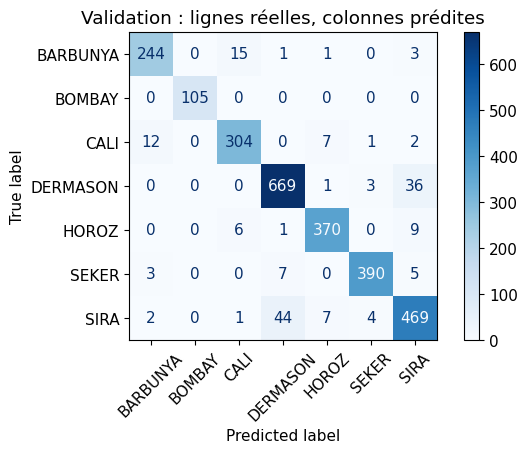

In [13]:
val_scores = model.evaluate(X_val_s, y_val, verbose=0, return_dict=True)
prob_val = model.predict(X_val_s, verbose=0)
pred_val = np.argmax(prob_val, axis=1)

print("Évaluation :", val_scores)
print("Probabilités :", prob_val.shape)
assert np.allclose(prob_val.sum(axis=1), 1, atol=1e-5)
print(classification_report(y_val, pred_val, target_names=class_names, digits=3, zero_division=0))
cm_val = confusion_matrix(y_val, pred_val, labels=np.arange(n_classes))
ConfusionMatrixDisplay(cm_val, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Validation : lignes réelles, colonnes prédites")
plt.show()

Fonctions create_model et summarize

In [15]:
def create_model(hidden=(32,), activation="relu", rate=0.001,
                 optimizer="adam", penalty=None, dropout=0.0, batchnorm=False,
                 input_dim=n_features, n_classes=n_classes):
    keras.utils.set_random_seed(SEED)
    net = keras.Sequential([keras.Input(shape=(input_dim,))])
    for units in hidden:
        net.add(layers.Dense(units, kernel_regularizer=penalty))
        if batchnorm:
            net.add(layers.BatchNormalization())
        net.add(layers.Activation(activation))
        if dropout > 0:
            net.add(layers.Dropout(dropout))
    net.add(layers.Dense(n_classes, activation="softmax"))
    opt = (keras.optimizers.Adam(learning_rate=rate) if optimizer == "adam"
           else keras.optimizers.SGD(learning_rate=rate))
    net.compile(optimizer=opt, loss="sparse_categorical_crossentropy",
                metrics=["accuracy"])
    return net

validation_loss = keras.losses.SparseCategoricalCrossentropy()
def summarize(name, net, hist):
    proba = net.predict(X_val_s, verbose=0)
    pred = proba.argmax(axis=1)
    return {"modèle": name, "paramètres": net.count_params(),
            "époques": len(hist.history["loss"]),
            "CE_validation": float(validation_loss(y_val, proba).numpy()),
            "accuracy_validation": accuracy_score(y_val, pred),
            "F1_macro_validation": f1_score(y_val, pred, average="macro")}

Taux d’apprentissage

**Interprétation :** Le taux 0,0001 avance lentement : sa perte part de 1,8 et descend doucement, il lui faut presque 30 époques pour se rapprocher des autres. Le taux 0,05 est instable : sa perte fait des sauts, mais elle ne diverge pas et reste autour de 0,2. Le taux 0,001 est le meilleur : sa courbe descend régulièrement et il a la perte la plus basse (0,18) et la meilleure accuracy (93,5 %).

{'modèle': 'Adam, taux=0.0001', 'paramètres': 775, 'époques': 30, 'CE_validation': 0.22442062199115753, 'accuracy_validation': 0.9268919911829537, 'F1_macro_validation': 0.937991888557919}
{'modèle': 'Adam, taux=0.001', 'paramètres': 775, 'époques': 30, 'CE_validation': 0.1791355162858963, 'accuracy_validation': 0.9353416605437178, 'F1_macro_validation': 0.9440528858825376}
{'modèle': 'Adam, taux=0.05', 'paramètres': 775, 'époques': 30, 'CE_validation': 0.22222593426704407, 'accuracy_validation': 0.9287288758265981, 'F1_macro_validation': 0.9378875194399644}


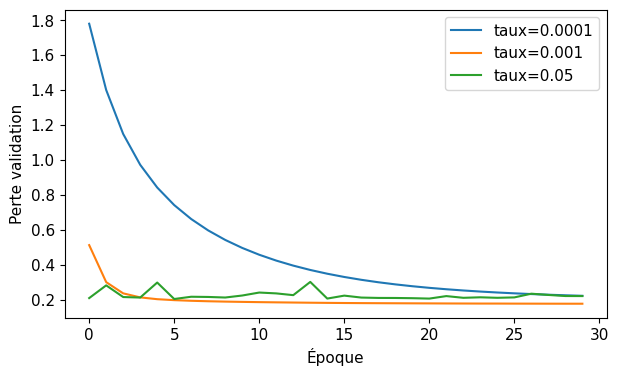

In [16]:
rate_runs = {}
for eta in [0.0001, 0.001, 0.05]:
    net = create_model(rate=eta)
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=30, batch_size=32, verbose=0)
    rate_runs[eta] = (net, hist)
    print(summarize(f"Adam, taux={eta}", net, hist))
    plt.plot(hist.history["val_loss"], label=f"taux={eta}")
plt.xlabel("Époque")
plt.ylabel("Perte validation")
plt.legend()
plt.show()

Adam vs SGD

In [17]:
optimizer_runs = {}
for opt in ["adam", "sgd"]:
    net = create_model(rate=0.001, optimizer=opt)
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=30, batch_size=32, verbose=0)
    optimizer_runs[opt] = (net, hist)
    print(summarize(opt, net, hist))

{'modèle': 'adam', 'paramètres': 775, 'époques': 30, 'CE_validation': 0.1791355162858963, 'accuracy_validation': 0.9353416605437178, 'F1_macro_validation': 0.9440528858825376}
{'modèle': 'sgd', 'paramètres': 775, 'époques': 30, 'CE_validation': 0.45739132165908813, 'accuracy_validation': 0.8986039676708303, 'F1_macro_validation': 0.9127455166665006}


Tailles des lots

**Interprétation :** Plus le lot est petit, plus il y a de mises à jour par époque. Avec le lot complet, le modèle ne fait que 10 mises à jour et n'apprend presque rien (2 %), alors que les lots de 1 et 32 dépassent 92 %. Le lot de 32 est le meilleur compromis entre vitesse et qualité.

In [18]:
batch_runs = {}
for size in [1, 32, len(y_train)]:
    net = create_model(rate=0.01, optimizer="sgd")
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=10, batch_size=size, verbose=0)
    batch_runs[size] = (net, hist)
    print(summarize(f"SGD, lot={size}", net, hist))
    print("Mises à jour par époque :", int(np.ceil(len(y_train) / size)))

{'modèle': 'SGD, lot=1', 'paramètres': 775, 'époques': 10, 'CE_validation': 0.18420544266700745, 'accuracy_validation': 0.9338721528288023, 'F1_macro_validation': 0.9435933096670807}
Mises à jour par époque : 8166
{'modèle': 'SGD, lot=32', 'paramètres': 775, 'époques': 10, 'CE_validation': 0.24625104665756226, 'accuracy_validation': 0.9261572373254959, 'F1_macro_validation': 0.9373532043967572}
Mises à jour par époque : 256
{'modèle': 'SGD, lot=8166', 'paramètres': 775, 'époques': 10, 'CE_validation': 2.153029680252075, 'accuracy_validation': 0.022777369581190303, 'F1_macro_validation': 0.01857896525460564}
Mises à jour par époque : 1


Architectures

**Interprétation :** Le réseau étroit (2 neurones) est le moins bon (91 %), car il est trop petit pour bien séparer 7 classes. Les trois autres modèles ont presque les mêmes scores (environ 93,5 %). Le réseau à deux couches a 4 fois plus de paramètres mais ne gagne presque rien : un plus grand réseau n'améliore donc pas toujours la généralisation.

In [19]:
architecture_runs = {}
for name, hidden, activation in [
        ("étroit", (2,), "relu"), ("référence", (32,), "relu"),
        ("deux couches", (64, 32), "relu"), ("tanh", (32,), "tanh")]:
    net = create_model(hidden=hidden, activation=activation)
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=30, batch_size=32, verbose=0)
    architecture_runs[name] = (net, hist)
    print(summarize(name, net, hist))

{'modèle': 'étroit', 'paramètres': 55, 'époques': 30, 'CE_validation': 0.34601786732673645, 'accuracy_validation': 0.9103600293901543, 'F1_macro_validation': 0.9161530629832253}
{'modèle': 'référence', 'paramètres': 775, 'époques': 30, 'CE_validation': 0.1791355162858963, 'accuracy_validation': 0.9353416605437178, 'F1_macro_validation': 0.9440528858825376}
{'modèle': 'deux couches', 'paramètres': 3399, 'époques': 30, 'CE_validation': 0.18276962637901306, 'accuracy_validation': 0.9382806759735489, 'F1_macro_validation': 0.9466792370174787}
{'modèle': 'tanh', 'paramètres': 775, 'époques': 30, 'CE_validation': 0.18017995357513428, 'accuracy_validation': 0.934974283614989, 'F1_macro_validation': 0.9438026846955491}


Régularisation

**Interprétation :** Les 5 modèles ont presque la même CE de validation (environ 0,18) et la même accuracy (environ 93,5 %). La régularisation n'apporte presque rien ici, car le modèle de référence ne surapprend pas. Pour L1 et L2, la perte d'evaluate est plus grande (0,21) car elle ajoute la pénalité sur les poids. Sur la courbe Dropout, la perte train est au-dessus de la validation : Dropout masque des neurones seulement pendant l'entraînement, ce qui rend le train plus difficile, alors qu'il est désactivé en validation.

{'modèle': 'référence', 'paramètres': 3399, 'époques': 35, 'CE_validation': 0.18359825015068054, 'accuracy_validation': 0.93791329904482, 'F1_macro_validation': 0.9469339596168754}
Perte evaluate, pénalité éventuelle incluse : 0.18359807133674622
{'modèle': 'L1', 'paramètres': 3399, 'époques': 35, 'CE_validation': 0.17847295105457306, 'accuracy_validation': 0.9390154298310066, 'F1_macro_validation': 0.9476335223050648}
Perte evaluate, pénalité éventuelle incluse : 0.21005816757678986
{'modèle': 'L2', 'paramètres': 3399, 'époques': 35, 'CE_validation': 0.17877866327762604, 'accuracy_validation': 0.9364437913299045, 'F1_macro_validation': 0.9457788528996175}
Perte evaluate, pénalité éventuelle incluse : 0.20822863280773163
{'modèle': 'Dropout', 'paramètres': 3399, 'époques': 35, 'CE_validation': 0.1787683069705963, 'accuracy_validation': 0.9375459221160911, 'F1_macro_validation': 0.9465067102998835}
Perte evaluate, pénalité éventuelle incluse : 0.1787680983543396
{'modèle': 'BatchNorm', 

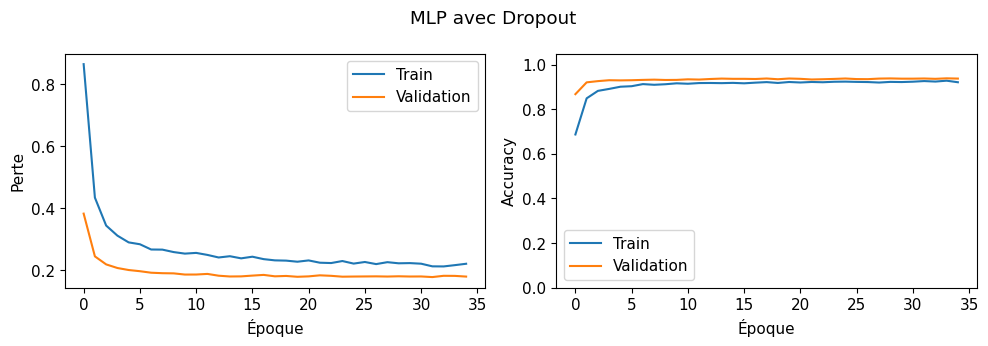

In [20]:
regularization_runs = {}
configs = [
    ("référence", {}),
    ("L1", {"penalty": keras.regularizers.l1(0.0001)}),
    ("L2", {"penalty": keras.regularizers.l2(0.001)}),
    ("Dropout", {"dropout": 0.25}),
    ("BatchNorm", {"batchnorm": True})
]
for name, options in configs:
    net = create_model(hidden=(64, 32), **options)
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=35, batch_size=32, verbose=0)
    regularization_runs[name] = (net, hist)
    print(summarize(name, net, hist))
    print("Perte evaluate, pénalité éventuelle incluse :",
          net.evaluate(X_val_s, y_val, verbose=0, return_dict=True)["loss"])
plot_history(regularization_runs["Dropout"][1], "MLP avec Dropout")

Diagnostic Dropout

**Interprétation :** En mode évaluation, deux prédictions sur les mêmes grains donnent le même résultat (True) car Dropout est désactivé. En mode entraînement, les résultats changent (False) car Dropout masque des neurones au hasard à chaque appel. C'est pour ça qu'on utilise predict ou evaluate pour la prédiction finale : les résultats sont stables.

In [21]:
probe = keras.Sequential([
    keras.Input(shape=(n_features,)), layers.Dense(16, activation="relu"),
    layers.Dropout(0.5), layers.Dense(n_classes, activation="softmax")
])
eval1 = probe(X_val_s[:8], training=False).numpy()
eval2 = probe(X_val_s[:8], training=False).numpy()
train1 = probe(X_val_s[:8], training=True).numpy()
train2 = probe(X_val_s[:8], training=True).numpy()
print("Évaluation identique :", np.allclose(eval1, eval2))
print("Entraînement identique :", np.allclose(train1, train2))

Évaluation identique : True
Entraînement identique : False


EarlyStopping

**Interprétation :** L'entraînement s'est arrêté à l'époque 74 au lieu de 100, car la perte de validation ne s'améliorait plus depuis l'époque 66. Le modèle garde les poids de la meilleure époque, avec 93,6 % d'accuracy.

Époques exécutées : 74
Meilleure époque : 66
{'accuracy': 0.9360764026641846, 'loss': 0.1774529367685318}


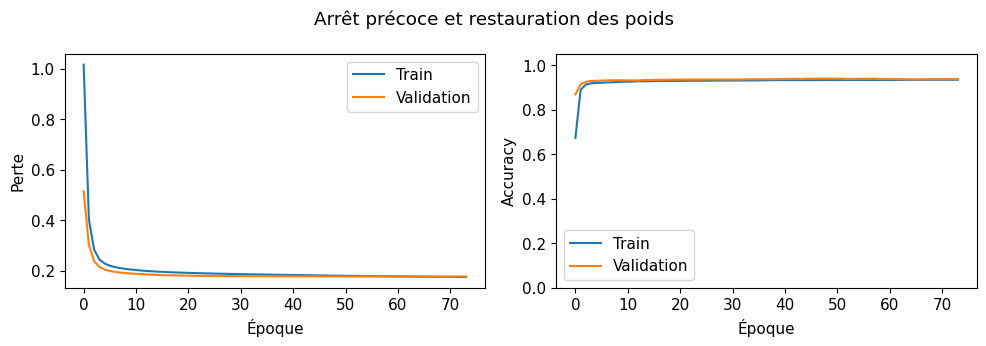

In [23]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=8,
                                           min_delta=0, restore_best_weights=True)
early_model = create_model()
early_history = early_model.fit(X_train_s, y_train,
                                validation_data=(X_val_s, y_val),
                                epochs=100, batch_size=32, verbose=0,
                                callbacks=[early_stop])
print("Époques exécutées :", len(early_history.history["loss"]))
print("Meilleure époque :", 1 + np.argmin(early_history.history["val_loss"]))
print(early_model.evaluate(X_val_s, y_val, verbose=0, return_dict=True))
plot_history(early_history, "Arrêt précoce et restauration des poids")

Sauvegarde et rechargement


**Interprétation :** Le modèle rechargé donne exactement les mêmes prédictions que le modèle d'origine (True) : la sauvegarde a bien conservé l'architecture et les poids. Le fichier .keras ne garde pas le scaler ni l'encodeur, c'est pour ça qu'on les sauvegarde à part pour pouvoir utiliser le modèle sur de nouveaux grains.

In [24]:
import joblib

early_model.save("modele_mlp_drybean.keras")
joblib.dump(scaler, "scaler_drybean.joblib")
joblib.dump(encoder, "encoder_drybean.joblib")

loaded_model = keras.models.load_model("modele_mlp_drybean.keras")

p_before = early_model.predict(X_val_s[:5], verbose=0)
p_after = loaded_model.predict(X_val_s[:5], verbose=0)
print("Prédictions conservées :", np.allclose(p_before, p_after, atol=1e-6))
assert np.allclose(p_before, p_after, atol=1e-6)

Prédictions conservées : True


Exemple d’utilisation

In [25]:
scaler_app = joblib.load("scaler_drybean.joblib")
encoder_app = joblib.load("encoder_drybean.joblib")
grain_brut = X_test[:1]
grain_s = scaler_app.transform(grain_brut)
proba = loaded_model.predict(grain_s, verbose=0)
print("Variété prédite :", encoder_app.inverse_transform(proba.argmax(axis=1))[0])

Variété prédite : DERMASON
